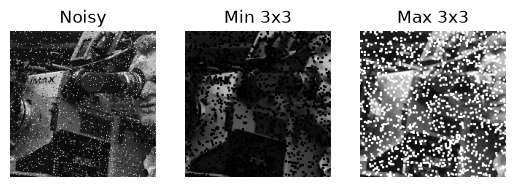

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("../../images/cameraman.png", 0)

noisy = img.copy()
mask = np.random.rand(*img.shape)
noisy[mask < 0.03] = 0       # pepper
noisy[mask > 0.97] = 255     # salt

k = np.ones((3, 3), np.uint8)
mn = cv2.erode(noisy, k)     # min filter
mx = cv2.dilate(noisy, k)    # max filter

crop = lambda x: x[100:300, 100:300]
for i, (im, t) in enumerate([(noisy, "Noisy"), (mn, "Min 3x3"), (mx, "Max 3x3")]):
    plt.subplot(1, 3, i + 1); plt.imshow(crop(im), cmap="gray", vmin=0, vmax=255); plt.title(t); plt.axis("off")
plt.show()